# №2 зертханалық жұмыс
## Деректерді алдын ала өңдеу: жетіспейтін мәндерді, санаттық белгілерді өңдеу, деректерді масштабтау және нормалау.

Мақсат — аралас деректерді ақпарат ағып кетпейтіндей дайындау, түрлендірулерді қолмен тексеру және бірыңғай конвейер құру.

Байланысты материалдар — 2-тарау, 2.9–2.10-бөлімдер, `lab02.py` скрипті. Жүктеме туралы барлық кесте — оқу синтетикасы. Деректер үшін интернет қажет емес. Ядроның таза күйінен бастап, ұяшықтарды ретімен орындаңыз. Графиктер мен CSV жергілікті `lab02_artifacts` каталогында сақталады.

Есептеулер мен түрлендірулер құрылымы тексеріледі. Автоматты өзіндік тексеру пәндік талдау мен есепті қорғауды алмастырмайды.

### 1-қадам. Орта және кіріс деректерінің келісімшарты
Кірістер — Цельсий градусындағы температура, сағатпен берілген жұмыс ұзақтығы, жолдық режим және жолдық ауысым. Екінші мысалдың жауабы — шартты бірліктердегі синтетикалық жүктеме. Жетіспейтін мән нөлге, ал жаңа санат жетіспейтін мәнге тең емес.

Келесі ұяшық орта нұсқаларын хабарлайды. Кітапханалар орнатылғаннан кейін Notebook сыртқы файлдарды жүктемей, жергілікті жұмыс істейді.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd() / "lab02_artifacts"
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"


from IPython.display import display, Image
from importlib.metadata import version
for package in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2


### 2–3-қадамдар. Өңдеудің екі тармағы
Сандық тармақ жетіспейтін мәндерді оқыту бөлігінің медианаларымен толықтырып, мәндерді масштабтайды. Санаттық тармақ жетіспейтін мәндерді модамен толықтырып, индикаторлар құрады. `handle_unknown="ignore"` жаңа мән үшін шығыс бағандарының санын сақтайды, бірақ модельге сол санат туралы пәндік мәлімет бермейді.

In [2]:
def make_preprocessor(scaler, numeric, categorical):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale", scaler)]), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("encode", OneHotEncoder(handle_unknown="ignore",
                                                    sparse_output=False))]), categorical)])



### Микрокесте
Оқыту жолдары: `(20,2,eco)`, `(NaN,4,standard)`, `(30,NaN,NaN)`, `(40,8,eco)`.
Жаңа жолдар: `(50,NaN,maintenance)` және `(NaN,6,eco)`.

Орындауға дейін медианалар мен стандарттау параметрлерін қолмен табыңыз. Медианалар 30 және 4-ке тең; толықтырудан кейін орташа мәндер 30 және 4,5. Стандартты ауытқулар √50 және √4,75. Алдымен тек бірінші кестеде оқыту жүргізіліп, кейін ережелер екінші кестеге қолданылады.

Микромысал: белгілер ['num__temperature_C', 'num__hours', 'cat__mode_eco', 'cat__mode_standard']
Transform-тен кейінгі жаңа жолдар:
 [[ 2.828427 -0.229416  0.        0.      ]
 [ 0.        0.688247  1.        0.      ]]


Медианалар [30.0, 4.0]
Орташа мәндер [30.0, 4.5]
Масштабтар [7.0710678118654755, 2.179449471770337]


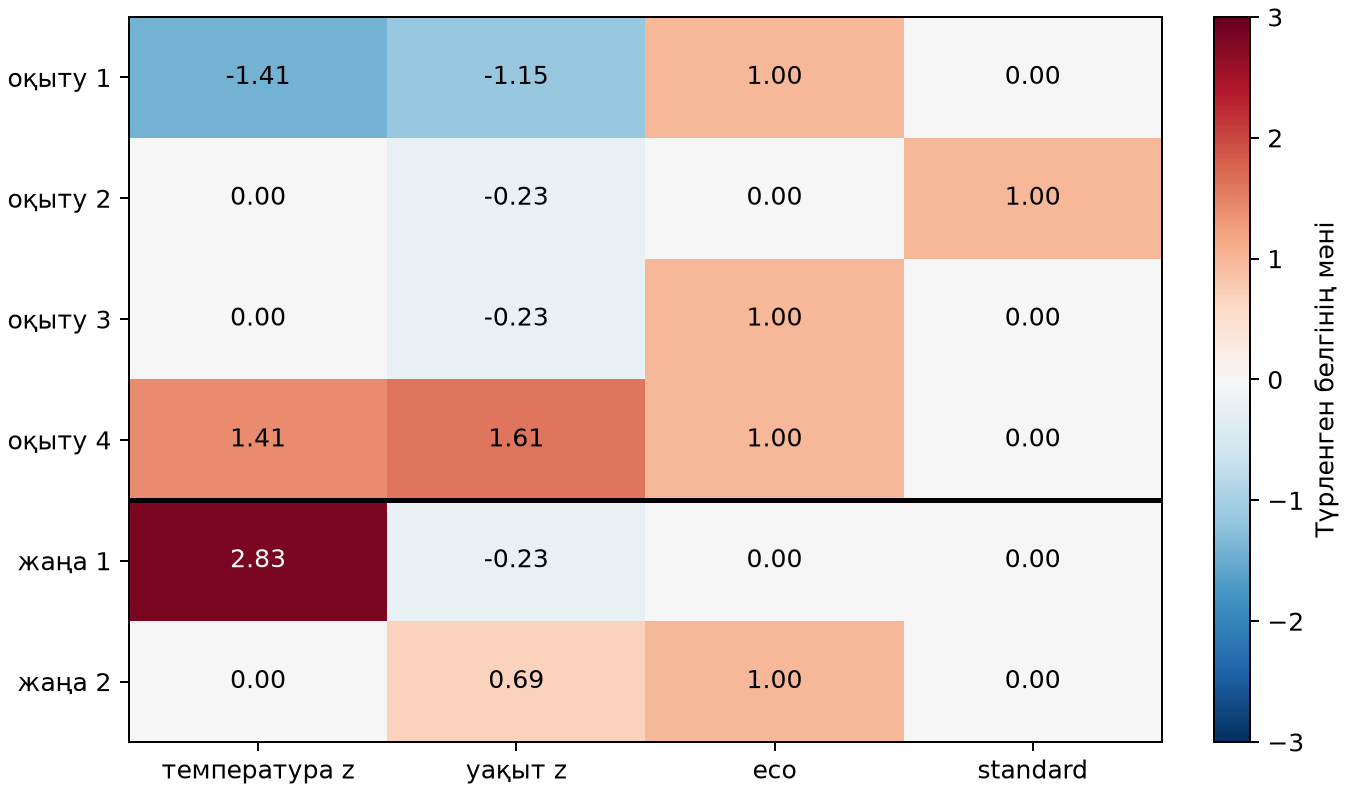

In [3]:
def micro_experiment():
    train = pd.DataFrame({"temperature_C": [20., np.nan, 30., 40.],
                          "hours": [2., 4., np.nan, 8.],
                          "mode": pd.Series(["eco", "standard", np.nan, "eco"], dtype=object)})
    new = pd.DataFrame({"temperature_C": [50., np.nan], "hours": [np.nan, 6.],
                        "mode": pd.Series(["maintenance", "eco"], dtype=object)})
    prep = make_preprocessor(StandardScaler(), ["temperature_C", "hours"], ["mode"])
    transformed_train = prep.fit_transform(train)
    medians_before = prep.named_transformers_["num"].named_steps["impute"].statistics_.copy()
    transformed_new = prep.transform(new)
    names = prep.get_feature_names_out().tolist()
    print("Микромысал: белгілер", names)
    print("Transform-тен кейінгі жаңа жолдар:\n", np.round(transformed_new, 6))
    numeric = prep.named_transformers_["num"]
    result = {"numeric_medians": numeric.named_steps["impute"].statistics_.tolist(),
              "numeric_means": numeric.named_steps["scale"].mean_.tolist(),
              "numeric_scales": numeric.named_steps["scale"].scale_.tolist(),
              "feature_names": names, "train_transformed": transformed_train.tolist(),
              "new_transformed": transformed_new.tolist(),
              "statistics_unchanged_after_transform": bool(np.array_equal(
                  medians_before, numeric.named_steps["impute"].statistics_))}
    values = np.vstack([transformed_train, transformed_new])
    fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
    image = ax.imshow(values, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
    ax.set(xticks=range(4), xticklabels=["температура z", "уақыт z", "eco", "standard"],
           yticks=range(6), yticklabels=["оқыту 1", "оқыту 2", "оқыту 3", "оқыту 4", "жаңа 1", "жаңа 2"])
    ax.axhline(3.5, color="black", linewidth=2)
    for i in range(6):
        for j in range(4):
            ax.text(j, i, f"{values[i,j]:.2f}", ha="center", va="center",
                    color="white" if abs(values[i,j])>1.7 else "black")
    fig.colorbar(image, ax=ax, label="Түрленген белгінің мәні")
    fig.savefig(FIGURES / "ch02_05_micro.png", dpi=180)
    plt.close(fig)
    return result


micro_result = micro_experiment()
print("Медианалар", micro_result["numeric_medians"])
print("Орташа мәндер", micro_result["numeric_means"])
print("Масштабтар", micro_result["numeric_scales"])
display(Image(filename=str(FIGURES / "ch02_05_micro.png")))


**Сіздің жауабыңыз.** Бірінші жаңа жолдың әр элементін түсіндіріңіз: `[2.828427, -0.229416, 0, 0]`. Медианамен толықтырылған ұзақтық стандарттаудан кейін неге нөлге тең емес? Режимнің нөлдік блогы нені білдіреді?

_Өз есептеуіңіз бен түсіндірмеңізді осында жазыңыз._

### 4–8-қадамдар. Жабдықтың синтетикалық жүктемесі
Seed 2026 арқылы 500 тәуелсіз бақылау генерацияланады. Жауап механизмі: `40 + 1.8*T + 5*h + a(mode) + 8*I(day) + noise`, шудың стандартты ауытқуы 5; режим түзетулері −10/0/15. Кірістердің бір бөлігі олардың мәніне тәуелсіз жасырылады. Деректер мен коэффициенттер нақты жабдықты сипаттамайды.

Fit-тен бұрын split 80/20, random_state 2026 қолданылады. Алдын ала екі конвейер берілген — медиана+StandardScaler және медиана+MinMaxScaler, екеуінде санаттық тармақ пен Ridge(alpha=1) бірдей. Қосымша DummyRegressor train орташа мәнін болжайды. Тест баптау және жеңімпазды таңдау үшін пайдаланылмайды.

Бүкіл жиынтықтағы жетіспейтін мәндер: {'temperature_C': 49, 'hours': 59, 'mode': 34, 'shift': 20}
approach       MAE      RMSE        R2
   Dummy 16.761519 21.265124 -0.030852
Standard  6.113983  8.325965  0.841974
  MinMax  6.180378  8.210417  0.846329


Параметрлер {'Standard': {'feature_names': ['num__temperature_C', 'num__hours', 'cat__mode_boost', 'cat__mode_eco', 'cat__mode_standard', 'cat__shift_day', 'cat__shift_night'], 'numeric_medians': [25.461118588823197, 7.5097601506465885], 'train_shape': [400, 7], 'test_shape': [100, 7], 'finite': True}, 'MinMax': {'feature_names': ['num__temperature_C', 'num__hours', 'cat__mode_boost', 'cat__mode_eco', 'cat__mode_standard', 'cat__shift_day', 'cat__shift_night'], 'numeric_medians': [25.461118588823197, 7.5097601506465885], 'train_shape': [400, 7], 'test_shape': [100, 7], 'finite': True}}


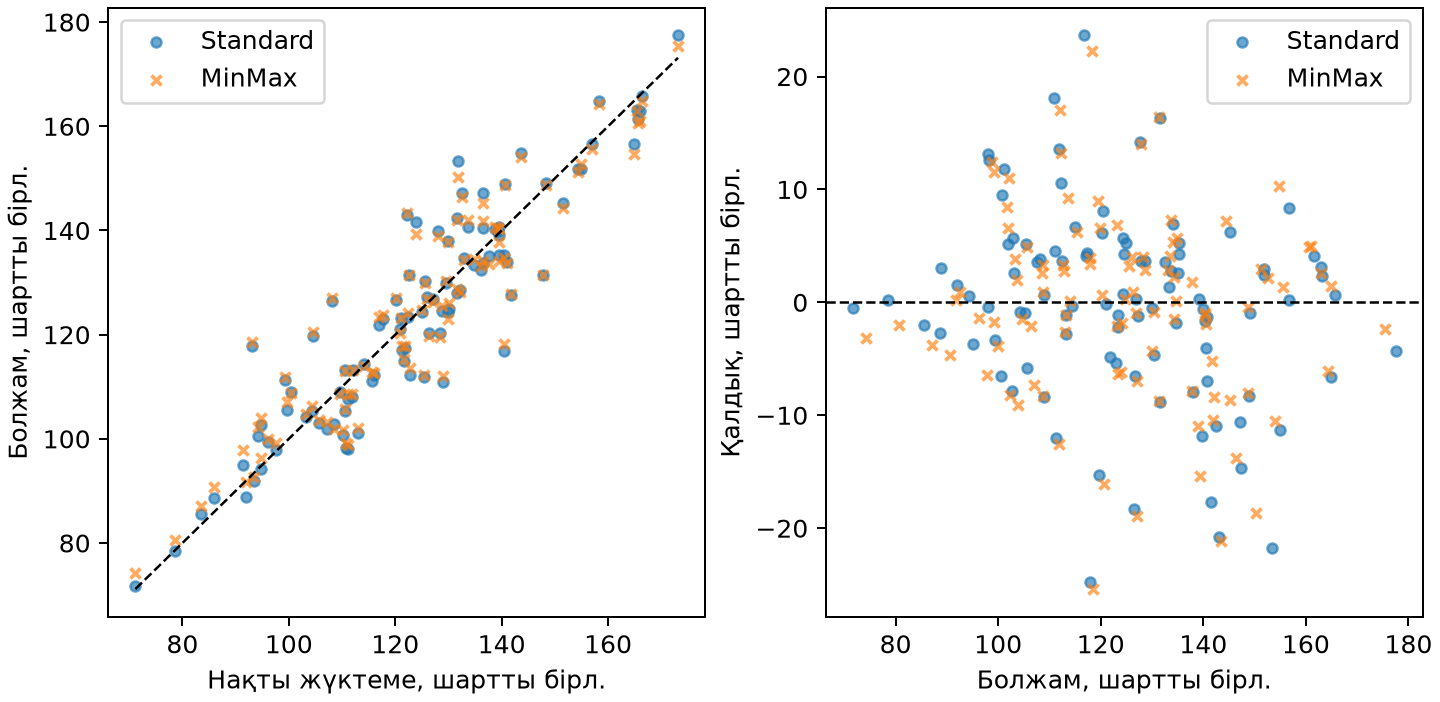

In [4]:
def make_equipment_data():
    rng = np.random.default_rng(2026)
    n = 500
    temperature = rng.normal(25, 6, n)
    hours = rng.uniform(1, 12, n)
    mode = rng.choice(["eco", "standard", "boost"], n, p=[.25, .5, .25])
    shift = rng.choice(["day", "night"], n, p=[.65, .35])
    effect = pd.Series(mode).map({"eco": -10, "standard": 0, "boost": 15}).to_numpy()
    y = 40 + 1.8*temperature + 5*hours + effect + 8*(shift=="day") + rng.normal(0, 5, n)
    X = pd.DataFrame({"temperature_C": temperature, "hours": hours,
                      "mode": pd.Series(mode, dtype=object),
                      "shift": pd.Series(shift, dtype=object)})
    for column, probability in {"temperature_C": .10, "hours": .12, "mode": .08, "shift": .05}.items():
        X.loc[rng.random(n)<probability, column] = np.nan
    return X, y

def equipment_experiment():
    X, y = make_equipment_data()
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.20, random_state=2026)
    numeric, categorical = ["temperature_C", "hours"], ["mode", "shift"]
    models = {"Dummy": DummyRegressor(strategy="mean")}
    for label, scaler in {"Standard": StandardScaler(), "MinMax": MinMaxScaler()}.items():
        models[label] = Pipeline([("prep", make_preprocessor(scaler, numeric, categorical)),
                                  ("model", Ridge(alpha=1.0))])
    rows, predictions, parameters = [], {}, {}
    for label, model in models.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        predictions[label] = pred
        rows.append({"approach": label, "MAE": mean_absolute_error(yte, pred),
                     "RMSE": np.sqrt(mean_squared_error(yte, pred)), "R2": r2_score(yte, pred)})
        if label != "Dummy":
            prep = model.named_steps["prep"]
            ztr, zte = prep.transform(Xtr), prep.transform(Xte)
            parameters[label] = {"feature_names": prep.get_feature_names_out().tolist(),
                                 "numeric_medians": prep.named_transformers_["num"].named_steps["impute"].statistics_.tolist(),
                                 "train_shape": list(ztr.shape), "test_shape": list(zte.shape),
                                 "finite": bool(np.isfinite(ztr).all() and np.isfinite(zte).all())}
    print("Бүкіл жиынтықтағы жетіспейтін мәндер:", X.isna().sum().to_dict())
    print(pd.DataFrame(rows).to_string(index=False))
    fig, axs = plt.subplots(1, 2, figsize=(8, 3.9), layout="constrained")
    for label, marker in [("Standard", "o"), ("MinMax", "x")]:
        pred = predictions[label]
        axs[0].scatter(yte, pred, s=16, alpha=.65, marker=marker, label=label)
        axs[1].scatter(pred, yte-pred, s=16, alpha=.65, marker=marker, label=label)
    limits = [float(yte.min()), float(yte.max())]
    axs[0].plot(limits, limits, "k--", linewidth=1)
    axs[1].axhline(0, color="black", linestyle="--", linewidth=1)
    axs[0].set(xlabel="Нақты жүктеме, шартты бірл.", ylabel="Болжам, шартты бірл.")
    axs[1].set(xlabel="Болжам, шартты бірл.", ylabel="Қалдық, шартты бірл.")
    axs[0].legend(); axs[1].legend()
    fig.savefig(FIGURES / "ch02_06_equipment.png", dpi=180)
    plt.close(fig)
    datasets = ROOT / "datasets"
    datasets.mkdir(parents=True, exist_ok=True)
    X.assign(load_synthetic=y).to_csv(datasets / "synthetic_equipment_load.csv", index=False)
    return {"synthetic": True, "seed": 2026, "rows": len(X), "train_size": len(ytr),
            "test_size": len(yte), "missing_counts": X.isna().sum().to_dict(),
            "train_missing_counts": Xtr.isna().sum().to_dict(), "metrics": rows,
            "fitted_parameters": parameters}


equipment_result = equipment_experiment()
print("Параметрлер", equipment_result["fitted_parameters"])
display(Image(filename=str(FIGURES / "ch02_06_equipment.png")))


Тексерілген тәжірибеде төрт өрістегі жетіспейтін мәндер саны 49/59/34/20. Оқытуда 400 жол, тестте 100 жол бар. Standard үшін MAE 6,113983 және RMSE 8,325965; MinMax үшін 6,180378 және 8,210417 алынды. Көрсеткіштер нұсқаларды әртүрлі ретпен орналастырады. Бекітілген alpha масштабпен өзара әсерлеседі, сондықтан тұтас конвейерлер салыстырылады.

**Сіздің жауабыңыз.** MAE мен RMSE айырмасын, толықтырғаннан кейін қателердің сақталуын және нақты өлшемдерге көшіру шекараларын түсіндіріңіз. Осы кесте бойынша жаңа alpha-ны неге таңдауға болмайды?

_Өз түсіндірмеңізді осында жазыңыз._

### Хаттаманы өзіндік тексеру
Микроесептеу, белгісіз санаттың көрінісі, transform-тен кейін статистикалардың өзгермеуі, шығыс матрицаларының өлшемдері және сандық емес шексіз мәндердің жоқтығы тексеріледі. Метрикалардың соңғы цифрына дейінгі дәл сәйкестігі басқа орта немесе өзгертілген нұсқа үшін әмбебап критерий емес.

In [5]:
assert np.allclose(micro_result["numeric_medians"], [30, 4])
assert np.allclose(micro_result["numeric_means"], [30, 4.5])
assert np.allclose(micro_result["new_transformed"][0][:2],
                   [20/np.sqrt(50), -0.5/np.sqrt(4.75)])
assert micro_result["new_transformed"][0][2:] == [0, 0]
assert micro_result["statistics_unchanged_after_transform"]
assert equipment_result["synthetic"] and equipment_result["rows"] == 500
assert equipment_result["train_size"] == 400 and equipment_result["test_size"] == 100
for parameters in equipment_result["fitted_parameters"].values():
    assert parameters["train_shape"] == [400, 7]
    assert parameters["test_shape"] == [100, 7]
    assert parameters["finite"]
print("Сандық түрлендірулер мен құрылымды өзіндік тексеру сәтті өтті.")


Сандық түрлендірулер мен құрылымды өзіндік тексеру сәтті өтті.


### 9-қадам. Жеке диагностика
Базалық тәжірибені сақтап, жеке ұяшықтар қосыңыз:

1. Температураның жетіспеу ықтималдығы 0,30: ақпарат жоғалуын түсіндіріңіз.
2. Train ішіндегі температура ауытқымалары: оқыту бөлігінде орташа мән мен медиананы салыстырыңыз.
3. Сандық мәндердің жоқтық индикаторлары: жаңа сигналды түсіндіріңіз.
4. Ауысымы белгілі жаңа режим санаты: нөлдік блокты зерттеңіз.
5. Кельвинмен берілген температура: бірліктер мен түрлендірулерді тексеріңіз.
6. Ауысымды алып тастау: санаттық ақпараттың жоғалуын түсіндіріңіз.

Өзгерістерді train ішінде зерттеңіз. Модель таңдау үшін бөлек валидация қажет. Бастапқы тест шексіз қайталама жақсартулар жиынтығына айналмайды.

**Нөміріңіз, гипотезаңыз, хаттамаңыз және қорытындыңыз.**

_Өз түсіндірмелеріңіз бен код ұяшықтарын қосыңыз._

### 10-қадам. Есеп және қорғау
Есеп құрамы — қойылым, деректер сөздігі, қол есептеуі, генератор, split хаттамасы, тармақтар схемасы, метрикалар, екі сурет, белгісіз санат, шектеулер, нұсқалар және таза қайта іске қосу.

Жергілікті рубрика: деректер сипаттамасы 15%; микромысал 15%; split және ақпарат ағуынан қорғау 20%; конвейер 20%; түсіндіру 20%; қайталанымдылық 10%. Барлығы жұмыс толықтығының 100%-ы. Ресми балдарды силлабус пен оқытушы анықтайды.

Бақылау сұрақтары — медиана қайдан алынады; амалдар реті қандай; стандарттаудан кейін медиана неге әрдайым нөл емес; жаңа режим қалай кодталады; бұл код неге білімді қалпына келтірмейді; белгі атауларын қалай білуге болады; шкалалар несімен ерекшеленеді; alpha масштабпен қалай байланысты; метрикалар неге әртүрлі рет береді; бір агрегаттың уақыттық өлшемдері үшін не өзгереді?

Дереккөздер — Оспан Ә.Ғ. авторлық 2-дәрісі және 2-зертханалық жұмысы; [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html), [Imputation](https://scikit-learn.org/stable/modules/impute.html). Құжаттама тексерілген күн — 2026 жылғы 4 қараша.